# Ejercicio 03 · Corpus público y clasificador de texto reproducible

**Autor:** Roberto Byas · **Asignatura:** INF-8239 Ciencia de Datos II · Unidad 02

**Pregunta de investigación.** ¿Puede un clasificador clásico (TF-IDF + modelo lineal) asignar el tipo de entidad de un resumen de Wikipedia entre 14 clases de la ontología de DBpedia, y en qué clases y por qué se equivoca?

**Cómo usar este notebook.** Se ejecuta *después* de `scripts/prepare_dbpedia.py` y `scripts/train_text.py` (ver README). Lee los artefactos de `reports/` y `models/`, recalcula las métricas sobre la misma partición (semilla 42) y comprueba que coinciden con lo guardado.

In [1]:
from __future__ import annotations

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split

from inf8239_u02.config import ROOT, settings
from inf8239_u02.data import load_dataset, sha256

pd.set_option("display.max_colwidth", 150)
CLASS_NAMES = ["Company", "EducationalInstitution", "Artist", "Athlete", "OfficeHolder",
               "MeanOfTransportation", "Building", "NaturalPlace", "Village", "Animal",
               "Plant", "Album", "Film", "WrittenWork"]
REPORTS = ROOT / "reports"
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: D:\Roberto Byas\Desktop\8239\INF8239_U02


## 1. Selección, licencia y trazabilidad

| Campo | Valor |
|---|---|
| Dataset | DBpedia14 (`fancyzhx/dbpedia_14`) |
| Fuente original | https://huggingface.co/datasets/fancyzhx/dbpedia_14 |
| Licencia | CC BY-SA 3.0 y GNU FDL (exige atribución y compartir igual) |
| Revisión fijada | commit `9abd46cf7fc8b4c64290f26993c540b92aa145ac` |
| Candidato descartado | Sentiment Labelled Sentences (UCI): solo 3,000 filas, tarea binaria sin clase neutra |

La decisión completa está en `docs/dataset_candidates.csv` y `docs/DATASET_CARD.md`.

In [2]:
data_path = Path(settings.dataset_path)
data_path = data_path if data_path.is_absolute() else ROOT / data_path
print("Archivo:", data_path)
print("SHA-256:", sha256(data_path))
print("Columnas de texto y etiqueta:", settings.text_column, "|", settings.target_column)
print("Semilla:", settings.random_state)

Archivo: D:\Roberto Byas\Desktop\8239\INF8239_U02\data\raw\dataset.csv
SHA-256: 96c4d8749f87221319d6cb49aad42a3cf63b8cf8759530725892d2ac72cfafce
Columnas de texto y etiqueta: content | label
Semilla: 42


## 2. Auditoría, duplicados y prevención de fuga

In [3]:
raw = load_dataset()
print("Filas y columnas:", raw.shape)
print("\nNulos:")
display(raw[[settings.text_column, settings.target_column]].isna().sum())

dups = raw.duplicated(subset=[settings.text_column]).sum()
print("Filas con texto duplicado:", dups)

grouped = raw[raw.duplicated(subset=[settings.text_column], keep=False)] \
    .groupby(settings.text_column)[settings.target_column].nunique()
print("Textos duplicados con etiquetas distintas (conflictos):", int((grouped > 1).sum()))

print("\nDistribución de clases:")
display(raw[settings.target_column].value_counts(normalize=True).sort_index().round(6))

lengths = raw[settings.text_column].str.len()
print("Longitud del texto (caracteres):")
display(lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1))

Filas y columnas: (630000, 5)

Nulos:


content    0
label      0
dtype: int64

Filas con texto duplicado: 138
Textos duplicados con etiquetas distintas (conflictos): 0

Distribución de clases:


label
0     0.071429
1     0.071429
2     0.071429
3     0.071429
4     0.071429
5     0.071429
6     0.071429
7     0.071429
8     0.071429
9     0.071429
10    0.071429
11    0.071429
12    0.071429
13    0.071429
Name: proportion, dtype: float64

Longitud del texto (caracteres):


count    630000.0
mean        281.4
std         137.7
min           3.0
50%         282.0
90%         458.0
99%         493.0
max       13561.0
Name: content, dtype: float64

In [4]:
# Misma limpieza y misma partición que scripts/train_text.py
df = raw.dropna(subset=[settings.text_column, settings.target_column])
df = df.drop_duplicates(subset=[settings.text_column])
counts = df[settings.target_column].value_counts()
stratify = df[settings.target_column] if counts.min() >= 2 else None
x_train, x_test, y_train, y_test = train_test_split(
    df[settings.text_column], df[settings.target_column], test_size=0.25,
    random_state=settings.random_state, stratify=stratify,
)
print(f"Tras limpiar: {len(df):,} filas | entrenamiento: {len(x_train):,} | prueba: {len(x_test):,}")
overlap = len(set(x_train) & set(x_test))
print("Textos idénticos entre entrenamiento y prueba:", overlap)
assert overlap == 0, "Hay fuga por textos duplicados entre particiones"

Tras limpiar: 629,862 filas | entrenamiento: 472,396 | prueba: 157,466
Textos idénticos entre entrenamiento y prueba: 0


**Prevención de fuga.** (1) Los duplicados se eliminan *antes* de dividir, y la celda anterior comprueba que no queda ningún texto idéntico entre entrenamiento y prueba. (2) El vectorizador TF-IDF vive dentro de cada `Pipeline`, así que se ajusta solo con los datos de entrenamiento. No se midieron cuasi-duplicados (textos casi iguales).

## 3. Baseline y dos pipelines comparables

Los tres modelos comparten el mismo vectorizador (TF-IDF de 1 a 2 gramas, `min_df=5`, sin límite de `max_features`) y la misma partición. Se entrenaron con `scripts/train_text.py`; aquí se leen sus métricas y se verifican con el modelo guardado.

In [5]:
metrics = pd.read_csv(REPORTS / "text_metrics.csv")
display(metrics.round(4))

,model,f1_macro
0,logistic,0.9844
1,naive_bayes,0.9696
2,dummy,0.0095


In [6]:
model = joblib.load(ROOT / "models" / "text_model.joblib")  # archivo generado por este mismo proyecto
pred = model.predict(x_test)
f1_check = f1_score(y_test, pred, average="macro")
f1_saved = float(metrics.loc[metrics["model"] == "logistic", "f1_macro"].iloc[0])
print(f"F1 macro recalculado: {f1_check:.6f} | guardado en text_metrics.csv: {f1_saved:.6f}")
assert np.isclose(f1_check, f1_saved, atol=1e-6), "El modelo guardado no corresponde a text_metrics.csv"
print("Errores:", int((pred != y_test.to_numpy()).sum()), "de", len(y_test))

F1 macro recalculado: 0.984429 | guardado en text_metrics.csv: 0.984429
Errores: 2452 de 157466


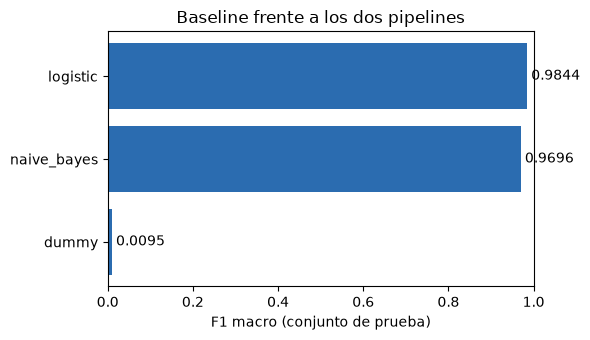

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(metrics["model"][::-1], metrics["f1_macro"][::-1], color="#2b6cb0")
ax.set_xlim(0, 1)
ax.set_xlabel("F1 macro (conjunto de prueba)")
for y, v in enumerate(metrics["f1_macro"][::-1]):
    ax.text(v + 0.01, y, f"{v:.4f}", va="center")
ax.set_title("Baseline frente a los dos pipelines")
plt.tight_layout()
plt.show()

## 4. Evaluación por clase y matriz de confusión

In [8]:
report = classification_report(y_test, pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
per_class["falsos_negativos"] = (per_class["support"] * (1 - per_class["recall"])).round().astype(int)
display(per_class.sort_values("recall").round(3))
print("Menor recall:", per_class["recall"].idxmin(), "| Menor precision:", per_class["precision"].idxmin())

,precision,recall,f1-score,support,falsos_negativos
Company,0.962,0.960,0.961,11249.0,446
Building,0.976,0.971,0.973,11249.0,323
Artist,0.968,0.972,0.970,11250.0,318
OfficeHolder,0.982,0.979,0.981,11250.0,233
WrittenWork,0.978,0.982,0.980,11246.0,207
EducationalInstitution,0.984,0.984,0.984,11248.0,184
Film,0.990,0.987,0.989,11250.0,142
Plant,0.992,0.990,0.991,11248.0,118
Athlete,0.995,0.991,0.993,11250.0,101
MeanOfTransportation,0.986,0.992,0.989,11249.0,95


Menor recall: Company | Menor precision: Company


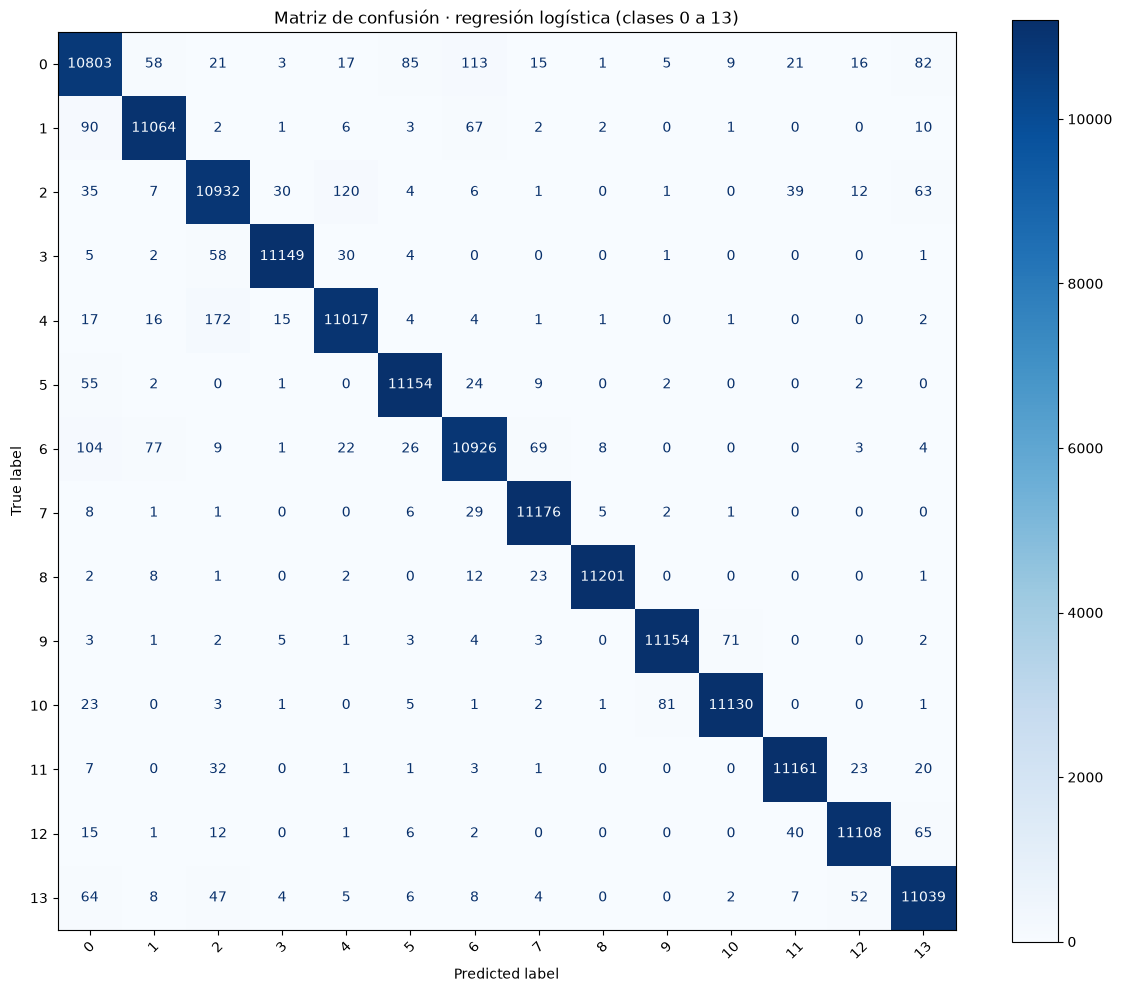

In [9]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, xticks_rotation=45, cmap="Blues", values_format="d", ax=ax,
)
ax.set_title("Matriz de confusión · regresión logística (clases 0 a 13)")
plt.tight_layout()
plt.show()

In [10]:
cm = pd.crosstab(pd.Series(y_test.to_numpy(), name="real"), pd.Series(pred, name="predicha"))
pairs = [(int(cm.loc[i, j]), CLASS_NAMES[i], CLASS_NAMES[j])
         for i in cm.index for j in cm.columns if i != j and cm.loc[i, j] > 0]
top = pd.DataFrame(sorted(pairs, reverse=True)[:8], columns=["casos", "clase_real", "clase_predicha"])
display(top)

,casos,clase_real,clase_predicha
0,172,OfficeHolder,Artist
1,120,Artist,OfficeHolder
2,113,Company,Building
3,104,Building,Company
4,90,EducationalInstitution,Company
5,85,Company,MeanOfTransportation
6,82,Company,WrittenWork
7,81,Plant,Animal


## 5. Análisis de 20 errores

La muestra de 20 errores (`reports/error_sample_20.csv`) se eligió con semilla 42 y reparto fijo entre los cruces más frecuentes (OfficeHolder→Artist 4, Artist→OfficeHolder 3, Company→Building 4, Building→Company 3, EducationalInstitution→Company 2, Company→MeanOfTransportation 2, Plant→Animal 2). **No es una muestra aleatoria de todos los errores**, por lo que sirve para formular hipótesis, no para estimar proporciones.

In [11]:
errors = pd.read_csv(REPORTS / "error_analysis.csv")
print("Errores totales en error_analysis.csv:", len(errors))

sample = pd.read_csv(REPORTS / "error_sample_20.csv")
sample["texto_resumido"] = sample["text"].str.slice(0, 150) + "..."
display(sample[["n", "real_nombre", "pred_nombre", "categoria_sugerida", "nota", "texto_resumido"]])

Errores totales en error_analysis.csv: 2452


,n,real_nombre,pred_nombre,categoria_sugerida,nota,texto_resumido
0,1,OfficeHolder,Artist,Error del modelo,El texto dice 'Member of Parliament'; el cargo es explicito y aun asi predijo Artist.,Francis James Roscoe (1831 – December 20 1878) was a Canadian entrepreneur and Member of Parliament.Francis Roscoe was born in Liverpool England ...
1,2,OfficeHolder,Artist,Etiqueta discutible,"Director General de un instituto de investigacion; perfil academico, no claramente un cargo publico.",Dr. Shenggen Fan (樊胜根) is the Director General of the International Food Policy Research Institute (IFPRI) since December 2009.He is known for hi...
2,3,OfficeHolder,Artist,Error del modelo,Menciona 'First Lady'; nada del texto sugiere un artista.,Zulema Maria Eva Menem is an Argentinian woman who played the role of First Lady during the presidency of her father Carlos Menem. Menem was born...
3,4,OfficeHolder,Artist,Etiqueta discutible,Una sola frase: 'philosopher'. El texto no sustenta OfficeHolder (ni Artist).,Luc Ferry (born January 1 1951) is a French philosopher and a notable proponent of Secular Humanism....
4,5,Artist,OfficeHolder,Etiqueta discutible,Periodista y redactora de discursos; la etiqueta Artist es dudosa y la prediccion OfficeHolder es razonable.,Elise Jordan is an American journalist political speechwriter and commentator. She served as a director for communications in the National Securi...
5,6,Artist,OfficeHolder,Ambiguedad entre clases,Abogado y miembro de la Academie francaise: encaja como cargo y como escritor.,Jean-Denis Bredin (born 17 May 1929) is a French attorney and founding partner of the firm Bredin Prat. He is the twentieth and current occupant ...
6,7,Artist,OfficeHolder,Ambiguedad entre clases,"Politico, escritor y periodista a la vez.",Mihal Grameno (January 13 1871 – February 5 1931) was an Albanian rilindas politician writer freedom fighter and journalist....
7,8,Company,Building,Ambiguedad entre clases,Hospital con razon social (Pvt. Ltd.): institucion y edificio.,The Mission Hospital (A Unit Of Durgapur Medical Centre Pvt. Ltd.) is a 250-bed hospital located in Durgapur West Bengal India....
8,9,Company,Building,Error del modelo,Fideicomiso de salud que opera farmacias; la palabra 'hospital' parece desviar la prediccion (hipotesis).,Hospital Pharmacy of North Norway Trust (Norwegian: Sykehusapotek Nord HF Northern Sami: Davvi Buohcceviessoapotehka) is a health trust owned by ...
9,10,Company,Building,Ambiguedad entre clases,Cerveceria: empresa y edificio historico a la vez.,The Three Tuns Brewery is a brewery in Bishop's Castle Shropshire England established in 1642 on its current site making it the oldest licensed b...


In [12]:
# Trazabilidad: las 20 filas revisadas deben pertenecer a esta misma ejecución
key = ["text", "real", "predicted"]
merged = sample.merge(errors[key].drop_duplicates(), on=key, how="left", indicator=True)
found = int((merged["_merge"] == "both").sum())
print(f"Filas de la muestra presentes en error_analysis.csv: {found} de {len(sample)}")
assert found == len(sample), (
    "La muestra no corresponde a este error_analysis.csv: vuelva a ejecutar scripts/train_text.py "
    "y revise que reports/ y models/ provengan de la misma ejecución."
)

Filas de la muestra presentes en error_analysis.csv: 20 de 20


,casos
categoria_sugerida,
Ambiguedad entre clases,9
Error del modelo,5
Etiqueta discutible,5
Texto insuficiente,1


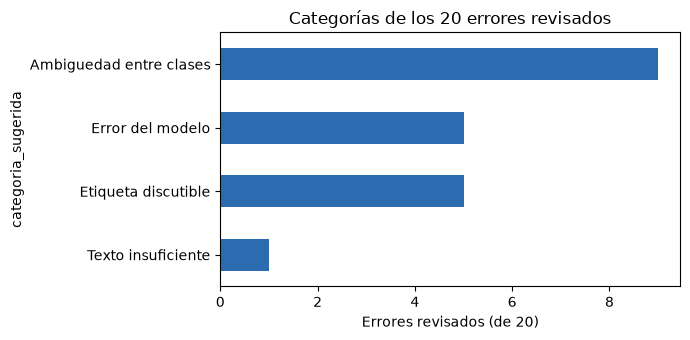

In [13]:
cat_counts = sample["categoria_sugerida"].value_counts()
display(cat_counts.to_frame("casos"))
fig, ax = plt.subplots(figsize=(7, 3.5))
cat_counts[::-1].plot.barh(ax=ax, color="#2b6cb0")
ax.set_xlabel("Errores revisados (de 20)")
ax.set_title("Categorías de los 20 errores revisados")
plt.tight_layout()
plt.show()

## 6. Interpretación

- **Observación.** La regresión logística obtiene el mejor F1 macro frente al baseline y a Naive Bayes; Company tiene el menor recall y la menor precision.
- **Evidencia.** Los errores se concentran en pares de clases cercanas (OfficeHolder↔Artist, Company↔Building). En los 20 errores revisados, la mayoría son ambigüedad entre clases o etiquetas discutibles, y una minoría son errores claros del modelo.
- **Interpretación.** Parte del error proviene de la ontología y de las etiquetas automáticas, no solo del modelo. La muestra no es aleatoria, así que esta es una hipótesis a verificar.
- **Decisión.** Aprobar solo para uso demostrativo, con la aplicación advirtiendo su alcance y revisión humana en los cruces señalados.
- **Limitaciones.** Inglés, Wikipedia de 2014, 14 tipos de entidad, etiquetas con ruido y un F1 muy alto que probablemente refleja una tarea fácil.
- **Siguiente verificación.** Validar con textos de otra fuente y revisar una muestra aleatoria de errores por clase.